# Getting started with `da6idb`

Reading and processing the files from APS 6-ID-B, with no viewer involved.

This runs against `tise2_2_00152`, the scan that travels with the repository:
a 101-point `psic_eta` rocking curve with its detector stack. Point
`FOLDER` somewhere else and the rest should follow.

In [1]:
import sys
from pathlib import Path

import numpy as np

# This notebook lives in examples/, so da6idb is one level up. Installing the
# package (pip install -e . from the repository root) makes this unnecessary,
# but the notebook should run either way.
REPO = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
try:
    import da6idb
except ModuleNotFoundError:
    sys.path.insert(0, str(REPO))
    import da6idb

FOLDER = REPO                # the repository root, which holds the example scan
SCAN = 152

## What is in the folder\n\n`open_folder` lists the scans; `summary()` is a DataFrame.

In [2]:
folder = da6idb.open_folder(FOLDER)
folder.summary().head(10)

,plan,motors,range,points,count_time,image,file
scan,,,,,,,
6,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 0→100 (101); rp100_ou...,101,1.0,True,tise2_2_00006_master.hdf
7,rel_scan,psic_eta,psic_eta 19.6295→23.6296 (101),101,1.0,True,tise2_2_00007_master.hdf
8,rel_scan,psic_eta,psic_eta 31.7869→35.787 (101),101,1.0,True,tise2_2_00008_master.hdf
9,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 100→0 (101); rp100_ou...,101,1.0,True,tise2_2_00009_master.hdf
10,rel_scan,psic_eta,psic_eta 31.8999→35.9 (101),101,1.0,True,tise2_2_00010_master.hdf
11,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 0→-50 (101); rp100_ou...,101,1.0,True,tise2_2_00011_master.hdf
34,grid_scan,"psic_eta, psic_chi",psic_eta 9.9→10.1 (25); psic_chi 89.9→90.1 (25),25,1.0,True,lineup_00034_master.hdf
83,scan,"rp100_output1_voltage_pv, rp100_output2_voltag...",rp100_output1_voltage_pv 50→-50 (101); rp100_o...,101,1.0,True,tise2_2_00083_master.hdf
151,rel_scan,cryo_z,cryo_z -1.49989→-1.09987 (41),41,1.0,True,tise2_2_00151_master.hdf


## One scan\n\nIndexing by scan number gives a `Scan`.

In [3]:
scan = folder[SCAN]
scan

<Scan 00152 'rel_scan' psic_eta — 101 points>

In [4]:
scan.hkl_position()     # where the diffractometer was, averaged over the scan

,mean,spread
axis,,
H,1.013464,0.002557
K,-0.492560,0.038620
L,7.484036,0.001328


## Which field is which

`fields` lists every name in the stream and says what it is, so you do not have
to guess at the names for x, y and `normalise`. The motor the scan moved comes
first, the detector the plan nominated (`hinted`) next, and the fields that
never moved last -- a channel that barely varies around a large positive value,
like an ion chamber, is your monitor.

In [5]:
scan.fields()

,role,hinted,units,varies,min,max,source
field,,,,,,,
psic_eta,scanned,False,degrees,True,2.069174e+01,2.269179e+01,PV:6idb1:m17.RBV
lambda250k_stats3_total,detector,True,,True,2.494060e+05,3.134790e+05,PV:s6lambda1:Stats3:Total_RBV
EPOCH,time,False,,True,1.790516e+09,1.790516e+09,
INDEX,index,False,,True,0.000000e+00,1.000000e+02,
Ion Chamber 4,detector,False,,True,1.338390e+05,1.342080e+05,PV:6idb1:scaler1.S5
Sawtooth_Bottom,detector,False,,True,1.442997e+06,1.443032e+06,PV:6idb1:scaler1.S6
ah2700a_capacitance,detector,False,,True,8.892000e-01,8.896600e-01,PV:6idb1:AH2700A:1:CAP
ah2700a_loss,detector,False,,True,0.000000e+00,1.800000e-03,PV:6idb1:AH2700A:1:LOSS
lambda250k_stats1_total,detector,False,,True,1.450500e+04,4.153100e+04,PV:s6lambda1:Stats1:Total_RBV


In [6]:
# just the plottable ones
table = scan.fields()
table[table["varies"] == True]

,role,hinted,units,varies,min,max,source
field,,,,,,,
psic_eta,scanned,False,degrees,True,2.069174e+01,2.269179e+01,PV:6idb1:m17.RBV
lambda250k_stats3_total,detector,True,,True,2.494060e+05,3.134790e+05,PV:s6lambda1:Stats3:Total_RBV
EPOCH,time,False,,True,1.790516e+09,1.790516e+09,
INDEX,index,False,,True,0.000000e+00,1.000000e+02,
Ion Chamber 4,detector,False,,True,1.338390e+05,1.342080e+05,PV:6idb1:scaler1.S5
Sawtooth_Bottom,detector,False,,True,1.442997e+06,1.443032e+06,PV:6idb1:scaler1.S6
ah2700a_capacitance,detector,False,,True,8.892000e-01,8.896600e-01,PV:6idb1:AH2700A:1:CAP
ah2700a_loss,detector,False,,True,0.000000e+00,1.800000e-03,PV:6idb1:AH2700A:1:LOSS
lambda250k_stats1_total,detector,False,,True,1.450500e+04,4.153100e+04,PV:s6lambda1:Stats1:Total_RBV


## Curves

`curve` takes an x field and any number of y fields, and normalises if asked.
Left to itself it uses the motor the scan moved -- or the point index, for a
plan that moved nothing.

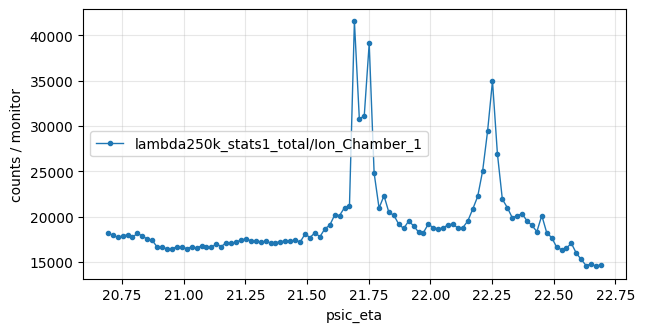

In [7]:
curve = scan.curve(y="lambda250k_stats1_total", normalise="Ion_Chamber_1")
ax = curve.plot(marker="o", ms=3, lw=1, figsize=(7, 3.5))
ax.set_ylabel("counts / monitor"); ax.grid(alpha=0.3)

In [8]:
scan.statistics("lambda250k_stats1_total")   # max, min, half-max centre and FWHM

,max_y,max_x,min_y,min_x,center,fwhm
lambda250k_stats1_total,41531.0,21.691766,14505.0,22.671743,21.722856,0.088734


## The detector frames

`images()` finds the detector file the way the viewers do, and brings the
ROIs the beamline recorded -- from the image file, or from the master's
baseline when the image has none.

In [9]:
images = scan.images()
print(images)
images.rois

<Images pva_tise2_2_00152.h5 — 101 x 516x516>


,name,x,y,w,h,angle
0,ROI1,286.0,335.0,50.0,5.0,0.0
1,ROI2,286.0,330.0,50.0,15.0,0.0
2,ROI3,111.0,333.0,400.0,10.0,0.0
3,ROI4,111.0,328.0,400.0,20.0,0.0


In [10]:
# every metric for ROI 1, frame by frame -- the same arithmetic the viewer runs
images.roi_series(0).head()

,sum,mean,min,max,comx,comy
frame,,,,,,
0,18152.0,72.608,20.0,128.0,24.369216,1.984134
1,17950.0,71.800,23.0,120.0,25.037047,1.959443
2,17688.0,70.752,22.0,123.0,24.960934,1.958390
3,17869.0,71.476,12.0,125.0,25.233309,1.968101
4,17972.0,71.888,25.0,162.0,25.629145,2.004618


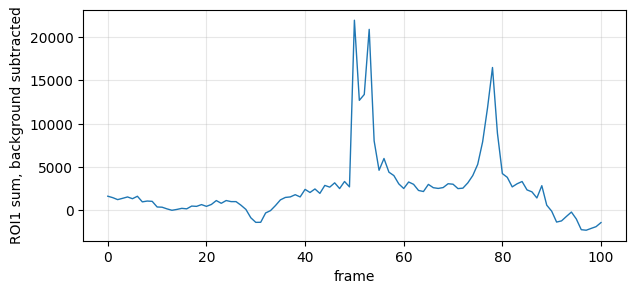

In [11]:
ax = images.roi_curve(0, "sum", background=2).plot(figsize=(7, 3), lw=1)
ax.set_ylabel("ROI1 sum, background subtracted"); ax.grid(alpha=0.3)

### Setting up your own ROI

`show` draws a frame the way the image viewer does -- x across, y down,
labelled in detector pixels -- with the ROIs the file records drawn on it.
Read a rectangle off those axes and hand it back as `(x, y, w, h)`:
everywhere an ROI index is taken, a rectangle is taken too, and reduced with
the same arithmetic.

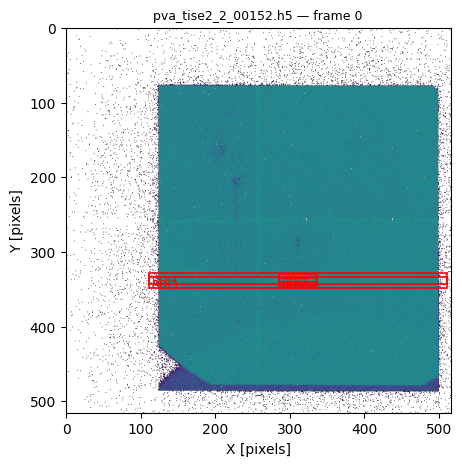

In [12]:
images.show(0, log=True);        # rois=() for a bare frame

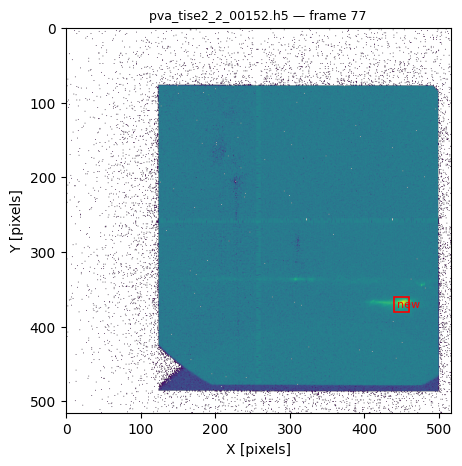

In [13]:
# the recorded ROIs are strips across y = 328-343, and they miss the
# spot near x = 440, y = 360 -- so put a box of our own on it
spot = (440, 360, 20, 20)                      # x, y, width, height
peak = int(images.roi_curve(spot, "sum").idxmax())
images.show(peak, rois=[spot], log=True);

### What the new ROI gives you

`roi_series` reduces every frame to all six metrics; `roi_curve` picks one
of them out as a series you can plot. The sum is the intensity in the box,
and the centre of mass says where inside the box it sat -- which is how you
see a spot drift across the ROI as the sample rocks.

In [14]:
images.roi_series(spot).head()

,sum,mean,min,max,comx,comy
frame,,,,,,
0,26365.0,65.9125,15.0,94.0,9.440698,9.538365
1,26746.0,66.8650,13.0,101.0,9.415838,9.531519
2,26805.0,67.0125,24.0,108.0,9.516396,9.444469
3,26686.0,66.7150,12.0,102.0,9.460316,9.487709
4,26328.0,65.8200,20.0,103.0,9.409032,9.491720


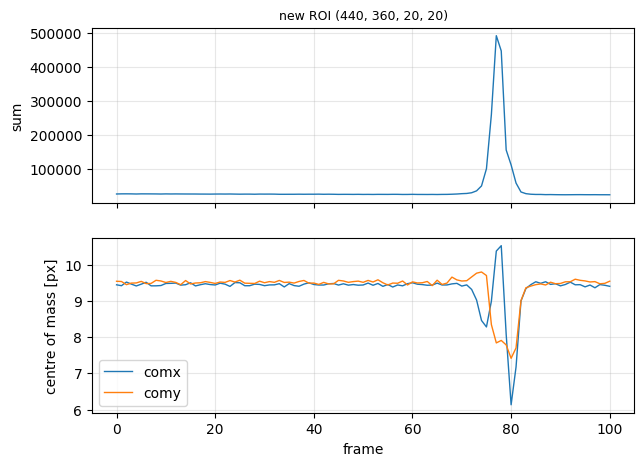

In [15]:
import matplotlib.pyplot as plt

series = images.roi_series(spot)
fig, (top, bottom) = plt.subplots(2, 1, sharex=True, figsize=(7, 5))
series["sum"].plot(ax=top, lw=1)
top.set_ylabel("sum"); top.set_title(f"new ROI {spot}", fontsize=9)
series[["comx", "comy"]].plot(ax=bottom, lw=1)
bottom.set_ylabel("centre of mass [px]"); bottom.set_xlabel("frame")
for a in (top, bottom): a.grid(alpha=0.3)

### Using a new ROI as the background

`background` takes a rectangle just as `roi` does, so an empty patch of
detector you pick yourself can be the background for a spot you pick
yourself. Its *mean per pixel* is what comes off: the sum loses that times
the signal ROI's pixel count, the other pixel-value metrics lose it once.
The centre of mass is deliberately left on the raw pixels -- weighting a
centroid by background-subtracted values goes unstable wherever the
corrected sum passes through zero.

Put the background box on the same part of the detector, off the spot: here
a box 30 pixels below reads a flat 60-70 counts per pixel all scan.

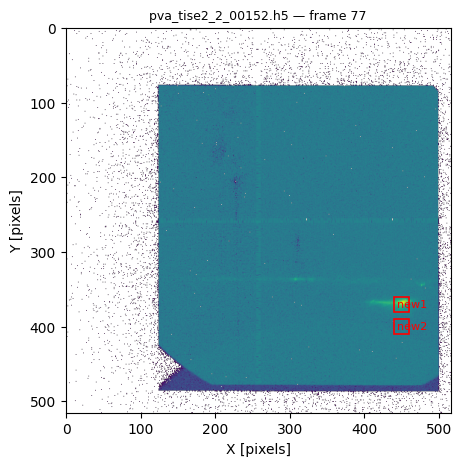

In [16]:
bg = (440, 390, 20, 20)                        # same size, just below
images.show(peak, rois=[spot, bg], log=True);

floor as a fraction of the peak: 4.9% raw, -0.4% corrected


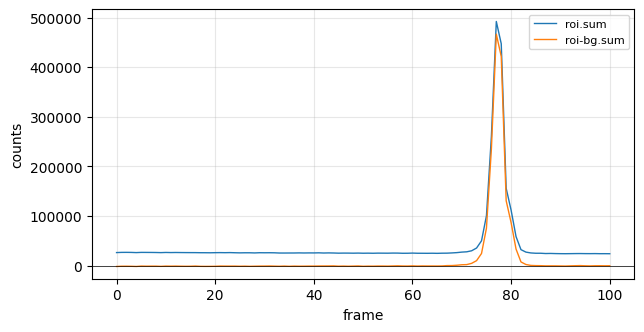

In [17]:
raw = images.roi_curve(spot, "sum")
corrected = images.roi_curve(spot, "sum", background=bg)

ax = raw.plot(figsize=(7, 3.5), lw=1, label=raw.name)
corrected.plot(ax=ax, lw=1, label=corrected.name)
ax.set_ylabel("counts"); ax.axhline(0, color="k", lw=0.5)
ax.legend(fontsize=8); ax.grid(alpha=0.3)

# off the peak the box is all background, so the correction should flatten it
print(f"floor as a fraction of the peak: "
      f"{raw.min() / raw.max():.1%} raw, {corrected.min() / corrected.max():.1%} corrected")

A fifth value rotates the rectangle about its corner, as the viewer's
handles do. `Rect` is the same thing with named fields, if you would rather
keep a few of them around.

sum     389967.062500
mean       974.917664
min         64.016792
max      17262.548828
comx        11.468725
comy         3.627773
Name: 77, dtype: float64

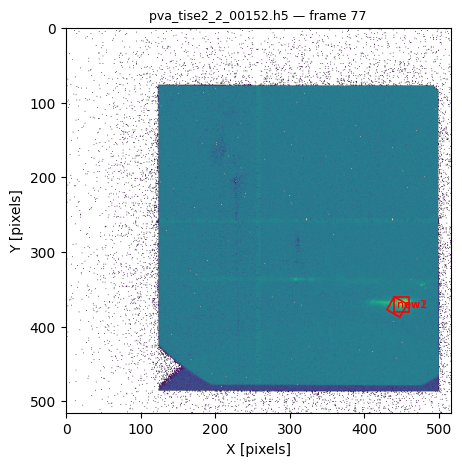

In [18]:
from da6idb import Rect

tilted = Rect(440, 360, 20, 20, angle=30)
images.show(peak, rois=[spot, tilted], log=True)
images.roi_series(tilted).loc[peak]

### The scattering angle of what is in the ROI

The detector circle reads the angle of one pixel: the centre. A spot
anywhere else is at a different two theta, and on a 2D detector that offset
is not along one axis only -- being off-centre across the detector counts
as well as being off-centre down it.

`two_theta_angles` asks xrayutilities where the ROI's centre of mass
actually points, through the same geometry the HKL conversion uses, so both
answer from one description of the instrument. `two_theta` averages the
scan into one number, weighted by intensity so the frames where the spot
was lit count for more than the ones holding only background. Either takes
any ROI, or `None` for the whole frame.

In [19]:
g = images.geometry()
print(f"delta circle reads  {g.detector_angles[1][0]:.5f} deg   (the centre pixel)")
print(f"centre pixel        {g.center_pixel}")
print(f"distance            {g.distance}  (pixel {g.pixel_widths()[1]})")

tth = images.two_theta_angles(spot)
print(f"\nspot at the peak    {tth[peak]:.5f} deg")
print(f"scan average        {images.two_theta(spot):.5f} deg")

delta circle reads  46.78862 deg   (the centre pixel)
centre pixel        (311.0, 338.0)
distance            838.25  (pixel 0.055)

spot at the peak    46.67871 deg
scan average        46.67464 deg


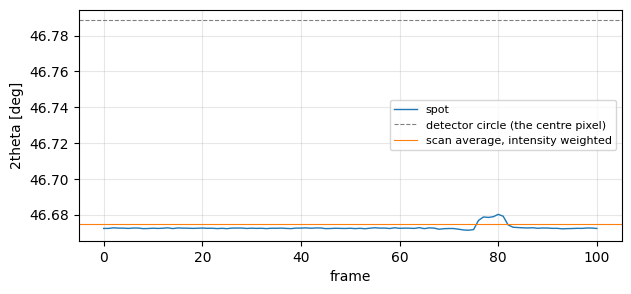

In [20]:
ax = tth.plot(figsize=(7, 3), lw=1, label="spot")
ax.axhline(g.detector_angles[1][0], color="grey", ls="--", lw=0.8,
           label="detector circle (the centre pixel)")
ax.axhline(images.two_theta(spot), color="C1", lw=0.8,
           label="scan average, intensity weighted")
ax.set_ylabel("2theta [deg]"); ax.legend(fontsize=8); ax.grid(alpha=0.3)

The spot is about 0.11 deg below the circle reading, because it sits
some 30 pixels below the centre pixel -- that offset is the whole point of
doing this rather than quoting the circle.

The small rise around frame 80 is the spot shifting inside the box as the
sample rocks, the same motion the centre of mass showed, now in degrees.
Away from the peak the box holds nothing but flat background, whose centre
of mass sits at the middle of the box: the angle there is the box's own
position, not a feature's, which is why the average is worth weighting by
intensity.

**Subtract the background.** Background spread evenly over the box has
its centre of mass at the *box's* centre, so when it is most of what the box
holds, the angle follows the box rather than the feature. If the box centre
and the feature sit on opposite sides of the detector's centre pixel, the
raw answer comes out the wrong side of the circle reading -- above it while
the spot is plainly below. Pass the same empty box used earlier:

In [21]:
bare = images.two_theta(spot)
clean = images.two_theta(spot, background=bg)
print(f"raw            {bare:.5f} deg")
print(f"-background    {clean:.5f} deg   ({(clean - bare) * 1000:+.1f} mdeg)")

raw            46.67464 deg
-background    46.67796 deg   (+3.3 mdeg)


## Reciprocal space

`hkl()` gathers the geometry from the master, the image file and any
`hkl_setup.json` in the folder, and says where each piece came from.

In [22]:
m = scan.hkl()
m.sources()

angles              image
center_pixel       master
detector_dirs       image
detector_size       image
distance           master
energy_kev         master
inplane             image
pixel_direction    master
primary_beam        image
sample_dirs         image
surface             image
transmission        image
ub                 master
Name: source, dtype: str

In [23]:
m.resolution()    # the cell the sampling supports, and what that was measured from

volume_per_sample    3.011909e-10
frame_gap            1.235297e-03
in_plane             4.937504e-04
cell                 6.703176e-04
footprint_H          3.645253e-04
footprint_K          1.336434e-03
footprint_L          5.620182e-04
dtype: float64

### A gridded map

`grid()` bins the frames onto a regular lattice and hands back an
`xarray.DataArray` with real H, K and L coordinates. It is cached as the same
`.vti` the viewers read, so a grid made here opens there.

`oversample` scales the automatic cell size; 4 keeps this example quick.

In [24]:
cube = m.grid(oversample=4.0)
cube

<xarray.DataArray 'intensity' (H: 91, K: 106, L: 138)> Size: 5MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]],
      shape=(91, 106, 138), dtype=float32)
Coordinates:
  * H        (H) float64 728B 0.9195 0.9221 0.9248 0.9275 ... 1.154 1.157 1.16
  * K        (K) float64 848B -0.6344 -0.6318 -0.6291 ... -0.3552 -0.3525
  * L        (L) float64 1kB 7.337 7.34 7.342 7.345 ... 7.697 7.7 7.702 7.705
Attributes:
    hkl_range:               [0.9194757806218079, 1.1596406031317914, -0.6344...
    step:                    [0.0026684980278887105, 0.002685092481490625, 0....
    width:                   [0.0003645252675839039, 0.0013364335217694867, 0...
    source_image:            pva_tise2_2_00152.h5
    source_master:           tise2_2_00152_master.hdf
    frames:                  101
    frame_range:             [0, -1, 1]
    geometry:                f203f0cd17684188
    oversample:              4.0
    transmission_corrected:  0
    filled_cells:            [445490, 1331148]
    path:                    /Users/jwkim/Library/CloudStorage/Box-Box/python...

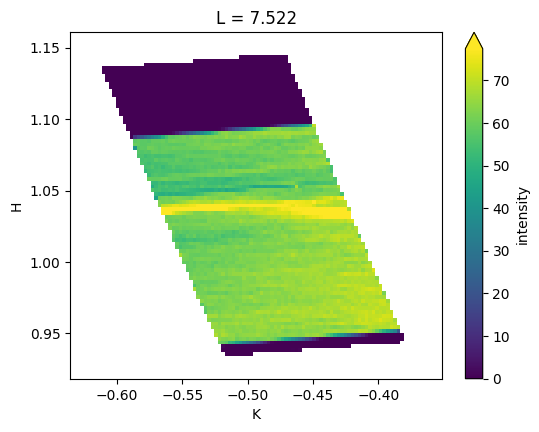

In [25]:
# select by coordinate rather than by index, and let xarray draw it
plane = cube.sel(L=float(cube.L[len(cube.L) // 2]), method="nearest")
plane.plot(figsize=(6, 4.5), robust=True)

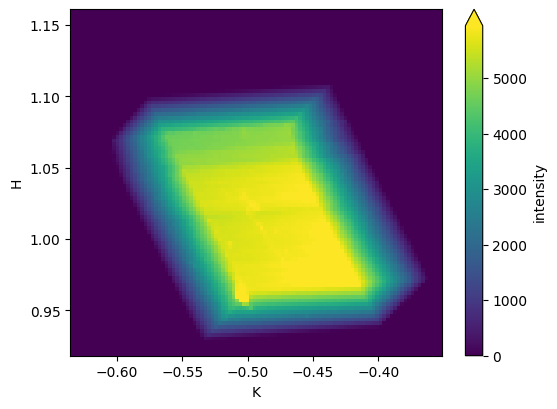

In [26]:
# or sum along an axis
cube.sum("L", skipna=True).plot(figsize=(6, 4.5), robust=True)

### Slices and cuts

`slice` cuts a plane at any angle, averaging over a slab of cells if asked.
Where an image axis runs along H, K or L it is labelled with it.

('K', 'H') (107, 91)


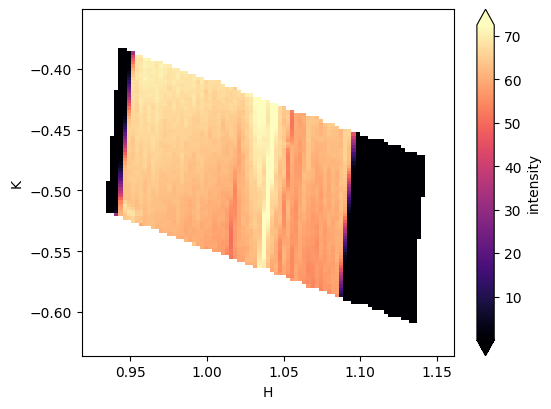

In [27]:
sl = m.slice(normal=(0, 0, 1), offset=0.0, layers=3)
print(sl.dims, sl.shape)

# .plot() is xarray's, so the colours are matplotlib's arguments: cmap picks
# the map, vmin/vmax set the range, robust=True takes the 2nd-98th percentile
# instead, and norm=LogNorm(...) makes it logarithmic. Cells the scan never
# reached are NaN, so they stay blank and stay out of the scaling.
sl.plot(figsize=(6, 4.5), cmap="magma", robust=True)

### A line cut between two points

`cut` takes the two H, K, L the line runs between, so the cut is something
you can write down and repeat on the next scan rather than aim at by hand.
It returns one row per sample -- distance from the start, where it is, and
what was there -- with NaN wherever the scan did not reach.

`width` averages that many parallel lines either side. Give it the slice's
`normal` and the widening stays in that plane instead of wandering out of
it.

In [28]:
cut = m.cut((0.96, -0.50, 7.52), (1.14, -0.50, 7.52), width=5, normal=(0, 0, 1))
print(cut.attrs)
cut.head()

{'start': [0.96, -0.5, 7.52], 'end': [1.14, -0.5, 7.52], 'width': 5}


,distance,H,K,L,intensity
0,0.000000,0.960000,-0.5,7.52,62.823627
1,0.002647,0.962647,-0.5,7.52,63.383362
2,0.005294,0.965294,-0.5,7.52,63.861365
3,0.007941,0.967941,-0.5,7.52,64.418054
4,0.010588,0.970588,-0.5,7.52,63.462140


peak at H 1.0394  K -0.5000  L 7.5200


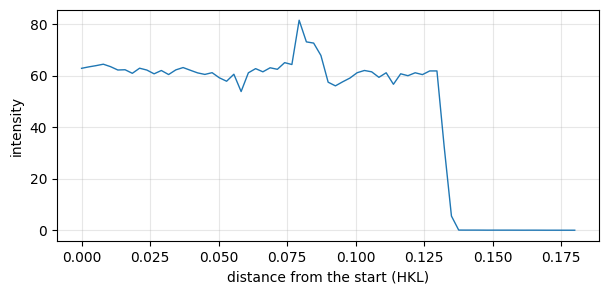

In [29]:
ax = cut.plot(x="distance", y="intensity", figsize=(7, 3), lw=1, legend=False)
ax.set_xlabel("distance from the start (HKL)"); ax.set_ylabel("intensity")
ax.grid(alpha=0.3)
peak = cut.loc[cut["intensity"].idxmax()]
print(f"peak at H {peak.H:.4f}  K {peak.K:.4f}  L {peak.L:.4f}")

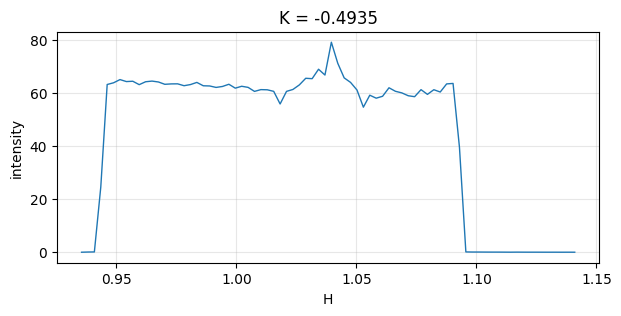

In [30]:
# a line through the slice is a one-liner once it is labelled
cut = sl.sel({sl.dims[0]: sl[sl.dims[0]][len(sl[sl.dims[0]]) // 2]}, method="nearest")
ax = cut.plot(figsize=(7, 3), lw=1); import matplotlib.pyplot as plt; plt.grid(alpha=0.3)

### Writing it out\n\nText, CSV, `.npz` or HDF5, each with a header saying where it came from.

In [31]:
from da6idb import export

out = export.write_dataarray(sl, "slice.txt")
print(out, "\n")
print("\n".join(open(out).read().splitlines()[:6]))

slice.txt 

# intensity from da6idb
# offset: 0.0
# layers: 3
# x axis: H  from 0.919476 to 1.159641  (91 points, step 0.0026685)
# y axis: K  from -0.634439 to -0.352504  (107 points, step 0.00265976)
# rows run along y, columns along x; unmeasured cells are nan


## A run of scans

`grid_scans` measures the cell size once, from the first scan, and reuses it
for the rest -- so with a common HKL range every grid shares origin, spacing
and shape, and they can be compared cell for cell.

In [32]:
from da6idb import batch

print(batch.expand_scans(152, 160, 2))
# batch.grid_scans(FOLDER, [152, 153], hkl_range=(0.95, 1.10, -0.60, -0.40, 7.40, 7.65))

[152, 154, 156, 158, 160]
